# Chapitre 10 - Exercices 10.7 à 10.12

Ce notebook traite les exercices 10.7 à 10.12 : valeurs des feuilles pour la perte
exponentielle, pas de Newton pour la déviance multinomiale, dérivation de l'algorithme 10.4
(gradient boosting à $K$ classes), le cas $K = 2$, le calcul rapide de la dépendance
partielle pour les arbres, et un exemple gaussien où l'espérance conditionnelle « invente »
un effet.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
set_style()

from esl import datasets
from esl.ch10_boosting import (AdaBoostM1, GradientBoosting, GradientBoostingMulticlass,
                               RegressionTree, simulate_nested_spheres,
                               partial_dependence_bruteforce)

## Exercice 10.7 : Valeurs des feuilles pour la perte exponentielle

**Énoncé (reformulé).** Établir l'expression (10.32) : lorsque les régions $R_{jm}$ d'un arbre
sont fixées, la solution de (10.30) pour la perte exponentielle est le log-rapport de cotes
pondéré dans chaque région,

$$\hat\gamma_{jm} = \frac12\log\frac{\sum_{x_i\in R_{jm}} w_i^{(m)} I(y_i = 1)}{\sum_{x_i\in R_{jm}} w_i^{(m)} I(y_i = -1)},
\qquad w_i^{(m)} = e^{-y_if_{m-1}(x_i)}.$$

**Rappel.** (10.30) : $\hat\gamma_{jm} = \arg\min_\gamma\sum_{x_i\in R_{jm}} L\big(y_i, f_{m-1}(x_i)+\gamma\big)$.

**Solution.** Avec $L(y,f) = e^{-yf}$ et $e^{a+b} = e^ae^b$ :

$$\sum_{x_i\in R_{jm}} e^{-y_i(f_{m-1}(x_i)+\gamma)} = \sum_{x_i\in R_{jm}} w_i^{(m)}e^{-y_i\gamma}
= e^{-\gamma}\,W_+ + e^{\gamma}\,W_-,$$

où $W_+ = \sum_{x_i\in R_{jm}} w_i^{(m)}I(y_i=1)$ et $W_- = \sum_{x_i\in R_{jm}} w_i^{(m)}I(y_i=-1)$ (on a
séparé les $y_i = 1$, pour lesquels $e^{-y_i\gamma} = e^{-\gamma}$, et les $y_i=-1$).

La fonction $\psi(\gamma) = W_+e^{-\gamma} + W_-e^{\gamma}$ est strictement convexe
($\psi'' = \psi > 0$) ; si $W_+>0$ et $W_->0$, elle tend vers $+\infty$ aux deux bouts et son
minimum est le zéro de $\psi'(\gamma) = -W_+e^{-\gamma} + W_-e^{\gamma}$ :

$$e^{2\gamma} = \frac{W_+}{W_-} \iff \hat\gamma_{jm} = \frac12\log\frac{W_+}{W_-}.$$

C'est (10.32) : la moitié du log-rapport de cotes **pondéré** dans la feuille, version
empirique de (10.16). Si la feuille est pure ($W_- = 0$ ou $W_+ = 0$), la valeur optimale
est infinie : en pratique on régularise (par exemple en ajoutant une petite constante aux deux sommes).

In [2]:
rng = np.random.RandomState(0)
yy = np.where(rng.rand(40) < 0.7, 1, -1)
ww = rng.exponential(size=40)
psi = lambda g: np.sum(ww * np.exp(-yy * g))
g_num = optimize.minimize_scalar(psi).x
g_formula = 0.5 * np.log(ww[yy == 1].sum() / ww[yy == -1].sum())
print("gamma numérique = %.6f ; formule (10.32) = %.6f" % (g_num, g_formula))

gamma numérique = 0.865083 ; formule (10.32) = 0.865083


**Illustration : un AdaBoost « à valeurs réelles ».** Utilisons (10.32) dans un boosting
d'arbres : à chaque étape, on prend les régions d'un arbre de moindres carrés pondérés
(avec les poids $w_i^{(m)}$) puis les valeurs (10.32) dans les feuilles, au lieu de $\pm\beta_m$.
C'est une variante proche du « Real AdaBoost » de Friedman et al. (2000).

In [3]:
def exp_tree_boost(X, y, M, J, Xt, yt, eps=1e-3):
    order = RegressionTree.presort(X)
    f, ft = np.zeros(len(y)), np.zeros(len(yt))
    errs = []
    for m in range(M):
        w = np.exp(-y * f)
        t = RegressionTree(J).fit(X, y, w, order=order)
        leaf = t.apply(X)
        for j in t.leaves:
            inl = leaf == j
            Wp = w[inl & (y == 1)].sum() + eps * w.mean()
            Wm = w[inl & (y == -1)].sum() + eps * w.mean()
            t.value[j] = 0.5 * np.log(Wp / Wm)        # (10.32), régularisé
        f += t.value[leaf]
        ft += t.predict(Xt)
        errs.append(np.mean(np.where(ft >= 0, 1, -1) != yt))
    return np.array(errs)

X, y = simulate_nested_spheres(2000, rng=np.random.RandomState(0))
Xt, yt = simulate_nested_spheres(5000, rng=np.random.RandomState(1))
err_real = exp_tree_boost(X, y, 200, 2, Xt, yt)
err_ada = AdaBoostM1(200, 2).fit(X, y).staged_errors(Xt, yt)

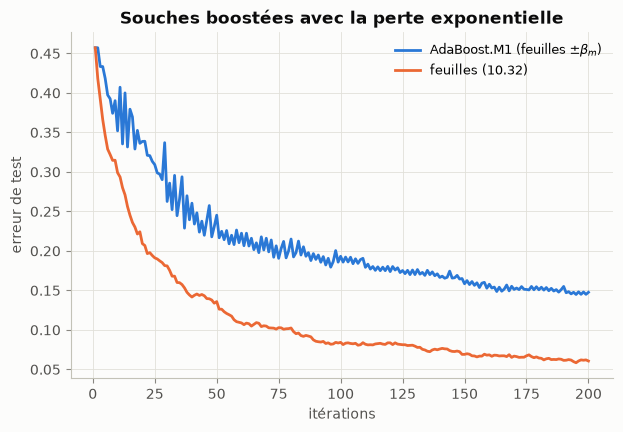

In [4]:
plt.figure(figsize=(7, 4.5))
plt.plot(np.arange(1, 201), err_ada, color=BLUE, label="AdaBoost.M1 (feuilles $\\pm\\beta_m$)")
plt.plot(np.arange(1, 201), err_real, color=ORANGE, label="feuilles (10.32)")
plt.title("Souches boostées avec la perte exponentielle")
plt.xlabel("itérations")
plt.ylabel("erreur de test")
plt.legend()
plt.show()

Laisser chaque feuille choisir sa propre valeur (au lieu d'un même $\pm\beta_m$ pour tout
l'arbre) accélère nettement la décroissance de l'erreur.

> **À retenir.** Pour la perte exponentielle et des régions fixées, la valeur optimale d'une
> feuille est la moitié du log-rapport de cotes pondéré $\frac12\log(W_+/W_-)$.

## Exercice 10.8 : Pas de Newton pour la déviance multinomiale

**Énoncé (reformulé).** Problème à $K$ classes, $y_{ik} = 1$ si l'observation $i$ est dans la
classe $k$, 0 sinon. Le modèle courant $f_k(x)$, $k=1,\dots,K$, vérifie $\sum_k f_k(x) = 0$ (voir
(10.21)). On veut le mettre à jour dans une région $R$ en ajoutant des constantes :
$f_k(x) + \gamma_k$, avec $\gamma_K = 0$.
(a) Écrire la log-vraisemblance multinomiale et ses dérivées premières et secondes.
(b) En n'utilisant que la diagonale du hessien et en partant de $\gamma = 0$, montrer qu'un
pas de Newton approché donne
$\gamma_k^1 = \dfrac{\sum_{x_i\in R}(y_{ik}-p_{ik})}{\sum_{x_i\in R}p_{ik}(1-p_{ik})}$, $k = 1,\dots,K-1$ (éq. (10.57)),
avec $p_{ik} = e^{f_k(x_i)}/\sum_\ell e^{f_\ell(x_i)}$.
(c) On préfère une mise à jour de somme nulle. Par un argument de symétrie, montrer que
$\hat\gamma_k = \frac{K-1}{K}\big(\gamma_k^1 - \frac1K\sum_{\ell=1}^K\gamma_\ell^1\big)$ (éq. (10.58)) convient, où $\gamma_k^1$
est défini par (10.57) pour **tous** les $k = 1,\dots,K$.

### (a) Log-vraisemblance et dérivées

Pour les observations de $R$, après mise à jour, $p_{ik}(\gamma) = \dfrac{e^{f_k(x_i)+\gamma_k}}{\sum_\ell e^{f_\ell(x_i)+\gamma_\ell}}$ et

$$\ell(\gamma) = \sum_{x_i\in R}\sum_{k=1}^K y_{ik}\log p_{ik}(\gamma)
= \sum_{x_i\in R}\Big[\sum_k y_{ik}(f_k(x_i)+\gamma_k) - \log\sum_\ell e^{f_\ell(x_i)+\gamma_\ell}\Big],$$

car $\sum_k y_{ik} = 1$. **Dérivée de la log-somme-exponentielle :**
$\frac{\partial}{\partial\gamma_k}\log\sum_\ell e^{f_\ell+\gamma_\ell} = \frac{e^{f_k+\gamma_k}}{\sum_\ell e^{f_\ell+\gamma_\ell}} = p_{ik}$. D'où

$$\frac{\partial\ell}{\partial\gamma_k} = \sum_{x_i\in R}\big(y_{ik} - p_{ik}\big),\qquad
\frac{\partial^2\ell}{\partial\gamma_k\partial\gamma_{k'}} = -\sum_{x_i\in R} p_{ik}\big(\delta_{kk'} - p_{ik'}\big),$$

en utilisant $\partial p_{ik}/\partial\gamma_{k'} = p_{ik}(\delta_{kk'} - p_{ik'})$ ($\delta_{kk'}=1$ si $k=k'$, 0 sinon,
dérivée d'un quotient). En particulier, la diagonale vaut $-\sum_{x_i\in R}p_{ik}(1-p_{ik})$.

### (b) Pas de Newton diagonal

La méthode de Newton pour maximiser $\ell$ fait $\gamma \leftarrow \gamma - H^{-1}\nabla\ell$. En
remplaçant $H$ par sa diagonale (de termes $-\sum p_{ik}(1-p_{ik}) < 0$), les coordonnées se
découplent et, en partant de $\gamma = 0$ (donc avec les $p_{ik}$ du modèle courant) :

$$\gamma_k^1 = 0 - \frac{\sum_{x_i\in R}(y_{ik}-p_{ik})}{-\sum_{x_i\in R}p_{ik}(1-p_{ik})}
= \frac{\sum_{x_i\in R}(y_{ik}-p_{ik})}{\sum_{x_i\in R}p_{ik}(1-p_{ik})},\qquad k=1,\dots,K-1,$$

c'est (10.57) ($\gamma_K = 0$ est fixé).

### (c) Symétrisation

Le choix $\gamma_K = 0$ est arbitraire : la classe $K$ joue un rôle particulier. Remarquons
que la vraisemblance est **invariante** par ajout d'une même constante à tous les $\gamma_k$
($p_{ik}$ ne change pas). Donc la mise à jour « avec la classe $K$ comme référence » est
équivalente à $\gamma_k^{(K)} - c$ pour toute constante $c$. Si l'on refait le calcul en prenant
chaque classe $r$ comme référence, on obtient les mêmes formules (10.57), mais les
directions diffèrent : dans le pas diagonal, la classe de référence reçoit 0 au lieu de $\gamma_r^1$.

Un choix **symétrique** (ne privilégiant aucune classe) consiste à calculer $\gamma_k^1$ par (10.57)
pour **toutes** les classes, puis à projeter sur l'hyperplan $\sum_k\gamma_k = 0$ en retirant la
moyenne : $\gamma_k^1 - \frac1K\sum_\ell\gamma_\ell^1$. Le facteur $\frac{K-1}{K}$ vient de ce que, parmi les $K$
paramétrisations (une par classe de référence), chaque coordonnée $k$ n'est réellement
mise à jour que dans $K-1$ d'entre elles (elle vaut 0 quand $k$ est la référence) :
en moyennant les $K$ mises à jour (centrées), on obtient

$$\hat\gamma_k = \frac{K-1}{K}\Big(\gamma^1_k - \frac1K\sum_{\ell=1}^K\gamma^1_\ell\Big).$$

Par construction $\sum_k\hat\gamma_k = 0$ : le modèle mis à jour reste de somme nulle.

**Vérification numérique** de la moyenne des $K$ paramétrisations, et comparaison avec le vrai
maximum de la log-vraisemblance dans la région (calculé par `scipy`).

In [5]:
rng = np.random.RandomState(0)
K = 4
nR = 60
F = rng.randn(nR, K) * 0.5
F -= F.mean(1, keepdims=True)                      # modèle courant de somme nulle
P = np.exp(F) / np.exp(F).sum(1, keepdims=True)
Ycls = np.array([rng.choice(K, p=pp) for pp in P])
Ycls[:20] = 0                                      # la région est enrichie en classe 0
Y = np.eye(K)[Ycls]
g1 = (Y - P).sum(0) / (P * (1 - P)).sum(0)         # (10.57) pour toutes les classes
g_hat = (K - 1) / K * (g1 - g1.mean())             # (10.58)

# moyenne des K mises à jour « classe r de référence », chacune recentrée
upd = []
for r in range(K):
    g = g1.copy()
    g[r] = 0.0
    upd.append(g - g.mean())
print("moyenne des K paramétrisations :", np.round(np.mean(upd, 0), 5))
print("formule (10.58)                 :", np.round(g_hat, 5), "| somme =", round(g_hat.sum(), 12))

moyenne des K paramétrisations : [ 0.81667  0.02833 -0.50002 -0.34499]
formule (10.58)                 : [ 0.81667  0.02833 -0.50002 -0.34499] | somme = 0.0


In [6]:
negll = lambda g: -np.sum(Y * np.log(np.exp(F + g) / np.exp(F + g).sum(1, keepdims=True)))
g_opt = optimize.minimize(negll, np.zeros(K)).x
g_opt -= g_opt.mean()
print("maximum exact (centré)          :", np.round(g_opt, 5))
for name, g in (("aucune mise à jour", np.zeros(K)), ("(10.57) centrée", g1 - g1.mean()),
                ("(10.58)", g_hat), ("exact", g_opt)):
    print("%-20s : -log-vraisemblance = %.4f" % (name, negll(g)))

maximum exact (centré)          : [ 0.73079  0.13271 -0.57979 -0.28371]
aucune mise à jour   : -log-vraisemblance = 79.2491
(10.57) centrée      : -log-vraisemblance = 73.8706
(10.58)              : -log-vraisemblance = 72.4908
exact                : -log-vraisemblance = 72.2900


Le pas (10.58) améliore fortement la vraisemblance par rapport à l'absence de mise à jour, et
s'approche de l'optimum exact ; le facteur $\frac{K-1}{K}$ « amortit » le pas diagonal, qui
a tendance à être trop long (les termes hors diagonale du hessien sont ignorés).

> **À retenir.** Gradient $\sum(y_{ik}-p_{ik})$, hessien diagonal $-\sum p_{ik}(1-p_{ik})$ ; le pas de
> Newton diagonal (10.57), centré et multiplié par $\frac{K-1}K$, donne une mise à jour symétrique de somme nulle.

## Exercice 10.9 : Dérivation de l'algorithme 10.4

**Énoncé (reformulé).** Pour $K$ classes codées $y_{ik}\in\{0,1\}$, avec la déviance
multinomiale (10.22) et la transformation logistique symétrique (10.21), reprendre les
arguments qui mènent à l'algorithme 10.3 pour obtenir l'algorithme 10.4 (indication :
exercice 10.8 pour l'étape 2(b)iii).

**Solution.** On suit l'algorithme 10.3, coordonnée par coordonnée.

1. *Initialisation.* $f_{k0} = 0$ pour tout $k$ : toutes les classes ont la même probabilité $1/K$
   (on pourrait aussi partir des log-fréquences centrées).
2. *Probabilités.* À l'itération $m$, $p_k(x) = e^{f_k(x)}/\sum_\ell e^{f_\ell(x)}$ (éq. (10.21)) : étape 2(a).
3. *Pseudo-résidus.* La déviance d'une observation est
   $L = -\sum_k y_{ik}f_k(x_i) + \log\sum_\ell e^{f_\ell(x_i)}$ (éq. (10.22)) ; d'après l'exercice 10.8(a),
   $-\partial L/\partial f_k(x_i) = y_{ik} - p_k(x_i)$ : c'est $r_{ikm}$ de l'étape 2(b)i (cf. (10.38)).
4. *Régions.* Comme en 10.3, on ajuste **un arbre de régression par classe** aux $r_{ikm}$ par
   moindres carrés : régions $R_{jkm}$ (étape 2(b)ii).

5. *Valeurs des feuilles.* On voudrait $\gamma_{jkm} = \arg\min\sum_{x_i\in R_{jkm}}L$, mais il n'y a pas de
   formule fermée. On utilise l'exercice 10.8 : un pas de Newton diagonal, symétrisé :
   $\gamma = \frac{K-1}{K}\cdot\frac{\sum(y_{ik}-p_{ik})}{\sum p_{ik}(1-p_{ik})}$ (en négligeant le terme de centrage, qui
   n'a pas de sens ici puisque les régions $R_{jkm}$ diffèrent d'une classe à l'autre).
   Il reste à exprimer le dénominateur avec les résidus : si $y_{ik} = 1$, $r_{ik} = 1-p_{ik}$ et
   $|r_{ik}|(1-|r_{ik}|) = (1-p_{ik})p_{ik}$ ; si $y_{ik} = 0$, $r_{ik} = -p_{ik}$ et $|r_{ik}|(1-|r_{ik}|) = p_{ik}(1-p_{ik})$.
   Dans les deux cas $p_{ik}(1-p_{ik}) = |r_{ik}|(1-|r_{ik}|)$, d'où l'étape 2(b)iii :

$$\gamma_{jkm} = \frac{K-1}{K}\,\frac{\sum_{x_i\in R_{jkm}} r_{ikm}}{\sum_{x_i\in R_{jkm}}|r_{ikm}|(1-|r_{ikm}|)}.$$

6. *Mise à jour* $f_{km}(x) = f_{k,m-1}(x) + \sum_j\gamma_{jkm}I(x\in R_{jkm})$ (étape 2(b)iv).

**Vérification de l'identité** $p(1-p) = |r|(1-|r|)$ et **mise en œuvre** : la classe
`GradientBoostingMulticlass` du module code l'algorithme 10.4 (avec rétrécissement). On
l'applique aux données *waveform* (3 classes) et on compare à scikit-learn.

In [7]:
pp = np.random.RandomState(0).rand(5)
for yk in (0, 1):
    r = yk - pp
    print("y = %d : max |p(1-p) - |r|(1-|r|)| = %.1e" % (yk, np.max(np.abs(pp * (1 - pp) - np.abs(r) * (1 - np.abs(r))))))

y = 0 : max |p(1-p) - |r|(1-|r|)| = 0.0e+00
y = 1 : max |p(1-p) - |r|(1-|r|)| = 0.0e+00


In [8]:
Xw, yw = datasets.load_waveform("train")
Xw_t, yw_t = datasets.load_waveform("test")
yw0, yw0_t = yw - 1, yw_t - 1                         # classes 0, 1, 2
gbk = GradientBoostingMulticlass(n_estimators=300, n_leaves=4, learning_rate=0.05).fit(Xw, yw0)
err_k = []
Fk = np.zeros((len(yw0_t), 3))
for row in gbk.trees_:
    for k, t in enumerate(row):
        Fk[:, k] += t.predict(Xw_t)
    err_k.append(np.mean(Fk.argmax(1) != yw0_t))
err_k = np.array(err_k)

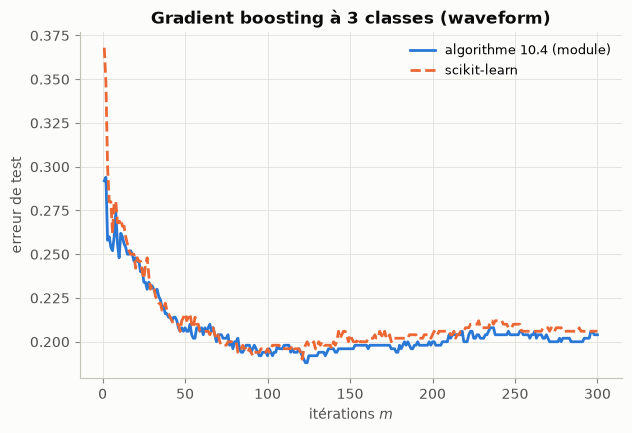

erreur de test finale : module 0.204, scikit-learn 0.206


In [9]:
from sklearn.ensemble import GradientBoostingClassifier
skg = GradientBoostingClassifier(n_estimators=300, max_leaf_nodes=4, learning_rate=0.05,
                                 random_state=0).fit(Xw, yw0)
err_sk = np.array([np.mean(p != yw0_t) for p in skg.staged_predict(Xw_t)])

plt.figure(figsize=(7, 4.5))
plt.plot(np.arange(1, 301), err_k, color=BLUE, label="algorithme 10.4 (module)")
plt.plot(np.arange(1, 301), err_sk, color=ORANGE, ls="--", label="scikit-learn")
plt.title("Gradient boosting à 3 classes (waveform)")
plt.xlabel("itérations $m$")
plt.ylabel("erreur de test")
plt.legend()
plt.show()
print("erreur de test finale : module %.3f, scikit-learn %.3f" % (err_k[-1], err_sk[-1]))

Les deux implémentations ont des performances semblables (les différences viennent de
l'initialisation, des critères de coupure et du détail du pas de Newton).

> **À retenir.** L'algorithme 10.4 = gradient boosting appliqué à chaque $f_k$ avec les
> pseudo-résidus $y_{ik}-p_{ik}$, et des valeurs de feuilles données par le pas de Newton
> symétrisé de l'exercice 10.8.

## Exercice 10.10 : Deux classes : un seul arbre par itération

**Énoncé (reformulé).** Montrer que pour $K = 2$, une seule régression par arbre suffit à
chaque itération du gradient boosting.

**Solution.** Avec $K=2$ et la contrainte $f_1 + f_2 = 0$, posons $f = f_1 = -f_2$. Alors

$$p_1 = \frac{e^{f}}{e^{f}+e^{-f}} = \frac{1}{1+e^{-2f}},\qquad p_2 = 1 - p_1.$$

- *Résidus.* Comme $y_{i2} = 1 - y_{i1}$ et $p_{i2} = 1 - p_{i1}$ : $r_{i2} = y_{i2} - p_{i2} = -(y_{i1} - p_{i1}) = -r_{i1}$.
- *Régions.* L'arbre de moindres carrés ajusté à $-r$ a les **mêmes coupures** que celui ajusté
  à $r$ (la somme des carrés intra-feuilles est invariante par changement de signe), avec des
  moyennes opposées.
- *Valeurs.* Dans l'étape 2(b)iii, le numérateur change de signe et le dénominateur
  $|r|(1-|r|)$ est inchangé : $\gamma_{j2m} = -\gamma_{j1m}$.

Par récurrence, $f_{2m} = -f_{1m}$ à chaque itération : le second arbre se déduit du premier.
Il suffit d'en construire un, et l'on retrouve le gradient boosting binomial sur la fonction
$2f$ (le log-rapport de cotes), avec le pas de Newton $\frac12\cdot\frac{\sum r}{\sum p(1-p)}$ sur l'échelle de $f$,
c'est-à-dire $\frac{\sum r}{\sum p(1-p)}$ sur l'échelle du log-rapport de cotes.

**Vérification numérique.** Données à deux classes **équilibrées** (pour que l'initialisation
du boosting binomial, $\log(\bar y/(1-\bar y))$, soit nulle comme celle de l'algorithme 10.4).

In [10]:
rng = np.random.RandomState(3)
X2 = rng.randn(400, 3)
y2 = np.r_[np.ones(200), np.zeros(200)].astype(int)
X2[y2 == 1] += 0.8
gbK2 = GradientBoostingMulticlass(n_estimators=8, n_leaves=4, learning_rate=0.3).fit(X2, y2)
same_regions = all(np.array_equal(r[0].feature, r[1].feature) and
                   np.allclose(r[0].threshold, r[1].threshold) for r in gbK2.trees_)
opposite_values = all(np.allclose(r[0].value[r[0].leaves], -r[1].value[r[1].leaves]) for r in gbK2.trees_)
print("mêmes régions pour les deux classes :", same_regions)
print("valeurs des feuilles opposées       :", opposite_values)
gb_bin = GradientBoosting("deviance", 8, 4, learning_rate=0.3).fit(X2, 1 - y2)   # classe 0 = « succès »
F2 = gbK2.decision_function(X2)
print("2 f_1 = log-rapport de cotes binomial :", np.allclose(2 * F2[:, 0], gb_bin.decision_function(X2)))

mêmes régions pour les deux classes : True
valeurs des feuilles opposées       : True
2 f_1 = log-rapport de cotes binomial : True


> **Remarque.** Nous nous limitons à quelques itérations : sur des exécutions plus longues,
> deux coupures peuvent avoir des gains égaux à l'arrondi machine près, et les deux
> programmes peuvent alors départager ces ex æquo différemment. L'égalité est
> mathématiquement exacte ; seules les erreurs d'arrondi la brisent.

> **À retenir.** Pour $K = 2$, $f_2 = -f_1$ à chaque étape : un seul arbre par itération,
> et l'on retrouve le gradient boosting binomial sur le log-rapport de cotes $2f_1$.

## Exercice 10.11 : Calcul rapide de la dépendance partielle

**Énoncé (reformulé).** Montrer comment calculer efficacement la fonction de dépendance
partielle $f_S(X_S)$ de (10.47) pour un modèle d'arbres.

**Le problème.** L'estimateur (10.48), $\bar f_S(x_S) = \frac1N\sum_i f(x_S, x_{iC})$, demande $N$
prédictions pour **chaque** point $x_S$ de la grille : un coût de l'ordre de
$N\times(\text{taille de la grille})\times M\times(\text{profondeur})$ pour $M$ arbres.

**Idée.** Un arbre est une somme de constantes sur des feuilles :
$T(x) = \sum_\ell v_\ell\, I(x\in R_\ell)$. Par linéarité,

$$\frac1N\sum_i T(x_S, x_{iC}) = \sum_\ell v_\ell\,\frac1N\sum_i I\big((x_S, x_{iC})\in R_\ell\big).$$

Chaque feuille $R_\ell$ est un pavé, intersection des conditions rencontrées sur le chemin
depuis la racine : $R_\ell = A_\ell^S\times A_\ell^C$, où $A_\ell^S$ ne porte que sur les variables de
$S$ et $A_\ell^C$ sur celles de $C$. Donc

$$\bar T_S(x_S) = \sum_\ell v_\ell\,I(x_S\in A_\ell^S)\,q_\ell,\qquad q_\ell = \frac1N\sum_i I(x_{iC}\in A_\ell^C).$$

**Algorithme exact.** Les $q_\ell$ ne dépendent pas de $x_S$ : on les calcule **une fois** par un
parcours de l'arbre où l'on propage un masque sur les observations, que l'on ne restreint
qu'aux coupures sur les variables de $C$. Ensuite, pour chaque point de grille, il suffit de
parcourir l'arbre en suivant les coupures sur $S$ et en descendant des deux côtés pour les
coupures sur $C$, puis de sommer $v_\ell q_\ell$ sur les feuilles atteintes. Le coût par point de
grille ne dépend plus de $N$.

**Algorithme de Friedman (sans les données).** On remplace $q_\ell$ par le produit, le long du
chemin, des fractions d'observations d'apprentissage passant dans chaque fils aux nœuds
qui coupent sur $C$ (fractions stockées dans l'arbre). C'est exact si, à chaque nœud, la
proportion qui part à gauche ne dépend pas des coupures sur $S$ faites plus haut (par
exemple si $X_S$ et $X_C$ sont indépendants) ; sinon c'est une approximation.

**Mise en œuvre** (méthode `partial_dependence` du module, avec ou sans les données) et
comparaison avec la force brute sur la simulation (10.2), où les variables sont indépendantes.

In [11]:
rng = np.random.RandomState(0)
Xs, ys = simulate_nested_spheres(2000, rng=rng)
gbp = GradientBoosting("deviance", 200, 6, learning_rate=0.1).fit(Xs, (ys + 1) // 2)
grid = np.linspace(-2.5, 2.5, 50)[:, None]

t0 = time.time(); pd_brute = partial_dependence_bruteforce(gbp.decision_function, Xs, [0], grid); t_brute = time.time() - t0
t0 = time.time(); pd_exact = gbp.partial_dependence(grid, [0], X=Xs); t_exact = time.time() - t0
t0 = time.time(); pd_fried = gbp.partial_dependence(grid, [0]); t_fried = time.time() - t0
print("force brute (10.48)    : %.2f s" % t_brute)
print("exact (q_l précalculés): %.2f s ; écart max à la force brute = %.1e" % (t_exact, np.max(np.abs(pd_exact - pd_brute))))
print("Friedman (sans données): %.2f s ; écart max à la force brute = %.3f" % (t_fried, np.max(np.abs(pd_fried - pd_brute))))

force brute (10.48)    : 1.03 s
exact (q_l précalculés): 0.01 s ; écart max à la force brute = 8.9e-16
Friedman (sans données): 0.00 s ; écart max à la force brute = 0.008


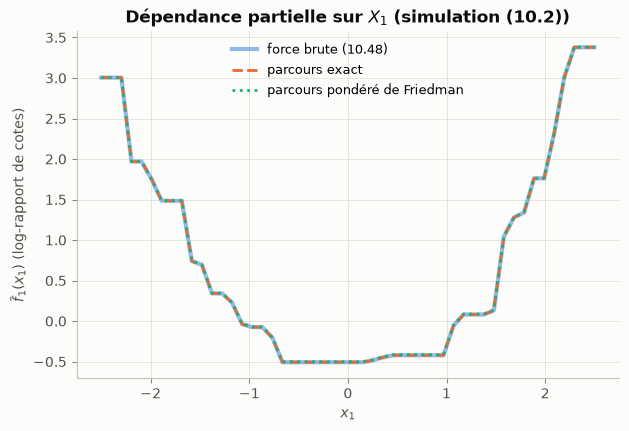

In [12]:
plt.figure(figsize=(7, 4.5))
plt.plot(grid[:, 0], pd_brute, color=BLUE, lw=3, alpha=0.5, label="force brute (10.48)")
plt.plot(grid[:, 0], pd_exact, color=ORANGE, ls="--", label="parcours exact")
plt.plot(grid[:, 0], pd_fried, color=COLORS[2], ls=":", label="parcours pondéré de Friedman")
plt.title("Dépendance partielle sur $X_1$ (simulation (10.2))")
plt.xlabel("$x_1$")
plt.ylabel("$\\bar f_{1}(x_1)$ (log-rapport de cotes)")
plt.legend()
plt.show()

Les trois calculs coïncident (à de petites fluctuations près pour la version de Friedman,
les variables étant indépendantes) ; les versions par parcours d'arbre sont bien plus
rapides que la force brute et s'appliquent sans changement à des grilles bidimensionnelles.

> **À retenir.** Pour un arbre, la dépendance partielle est une somme sur les feuilles de
> $v_\ell\, I(x_S\in A^S_\ell)\, q_\ell$ ; on l'obtient par un parcours de l'arbre qui suit les
> coupures sur $S$ et « se dédouble » sur les coupures sur $C$.

## Exercice 10.12 : Un effet « inventé » par l'espérance conditionnelle

**Énoncé (reformulé).** Dans (10.49), prenons $S=\{1\}$, $C = \{2\}$ et $f(X_1,X_2) = X_1$. On suppose
$(X_1, X_2)$ gaussien, chaque variable de moyenne nulle et de variance 1, et $E(X_1X_2) = \rho$.
Montrer que $E\big(f(X_1,X_2)\mid X_2\big) = \rho X_2$, bien que $f$ ne dépende pas de $X_2$.

**Rappel (vecteur gaussien).** Si $(X_1, X_2)$ est gaussien centré avec $\mathrm{Var}(X_1) = \mathrm{Var}(X_2) = 1$ et
$\mathrm{Cov}(X_1,X_2) = \rho$, posons $Z = X_1 - \rho X_2$. Le couple $(Z, X_2)$ est gaussien (image
linéaire d'un vecteur gaussien) et

$$\mathrm{Cov}(Z, X_2) = \mathrm{Cov}(X_1, X_2) - \rho\,\mathrm{Var}(X_2) = \rho - \rho = 0.$$

Pour un vecteur gaussien, covariance nulle équivaut à indépendance : $Z$ est **indépendante** de $X_2$.

**Solution.** On écrit $X_1 = \rho X_2 + Z$. Par linéarité de l'espérance conditionnelle,

$$E(X_1\mid X_2) = \rho\,E(X_2\mid X_2) + E(Z\mid X_2) = \rho X_2 + E(Z) = \rho X_2,$$

car $X_2$ est une fonction de $X_2$ (donc $E(X_2\mid X_2) = X_2$), $Z$ est indépendante de $X_2$
(donc $E(Z\mid X_2) = E(Z)$) et $E(Z) = E(X_1) - \rho E(X_2) = 0$.

Ainsi $\tilde f_C(X_2) = E(f\mid X_2) = \rho X_2$ : l'espérance conditionnelle attribue à $X_2$ un effet
linéaire de pente $\rho$, alors que $f$ ne dépend pas du tout de $X_2$. En revanche, la
dépendance partielle (10.47) sur $X_2$ vaut $E_{X_1}(X_1) = 0$ : elle est constante, comme il se doit.

In [13]:
rng = np.random.RandomState(0)
for rho in (0.3, 0.8):
    Z = rng.randn(50000, 2)
    X12 = np.c_[Z[:, 0], rho * Z[:, 0] + np.sqrt(1 - rho ** 2) * Z[:, 1]]   # corr(X1, X2) = rho
    slope = np.polyfit(X12[:, 1], X12[:, 0], 1)[0]
    print("rho = %.1f : corrélation empirique %.3f ; pente de la régression de X1 sur X2 = %.3f"
          % (rho, np.corrcoef(X12.T)[0, 1], slope))

rho = 0.3 : corrélation empirique 0.305 ; pente de la régression de X1 sur X2 = 0.306
rho = 0.8 : corrélation empirique 0.799 ; pente de la régression de X1 sur X2 = 0.798


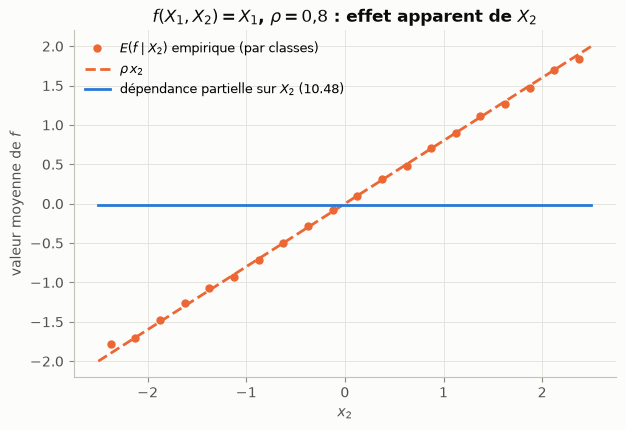

In [14]:
rho = 0.8
Z = rng.randn(20000, 2)
X1 = Z[:, 0]
X2 = rho * X1 + np.sqrt(1 - rho ** 2) * Z[:, 1]
A = np.c_[X1, X2]
f = lambda B: B[:, 0]
g2 = np.linspace(-2.5, 2.5, 26)
pd2 = partial_dependence_bruteforce(f, A[:3000], [1], g2[:, None])
edges = np.linspace(-2.5, 2.5, 21)
mid = 0.5 * (edges[1:] + edges[:-1])
idx = np.digitize(X2, edges)
cond = np.array([X1[idx == k].mean() for k in range(1, len(edges))])

plt.figure(figsize=(7, 4.5))
plt.plot(mid, cond, "o", color=ORANGE, ms=5, label="$E(f\\mid X_2)$ empirique (par classes)")
plt.plot(g2, rho * g2, color=ORANGE, ls="--", label="$\\rho\\,x_2$")
plt.plot(g2, pd2, color=BLUE, label="dépendance partielle sur $X_2$ (10.48)")
plt.title("$f(X_1,X_2) = X_1$, $\\rho = 0{,}8$ : effet apparent de $X_2$")
plt.xlabel("$x_2$")
plt.ylabel("valeur moyenne de $f$")
plt.legend()
plt.show()

> **À retenir.** L'espérance conditionnelle mesure l'effet de $X_S$ **en ignorant** les
> autres variables : elle reflète aussi l'effet des variables corrélées à $X_S$. Ici elle
> « invente » un effet $\rho X_2$ ; la dépendance partielle, elle, est plate.